<a href="https://colab.research.google.com/github/eileen795/MSSP-6070/blob/main/practise8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [3]:
url = "https://raw.githubusercontent.com/eileen795/MSSP-6070/main/Modules/week8/InternetSales%20%282%29.csv"
df = pd.read_csv(url, encoding="cp1252")
df.columns
df.info()

/tmp/ipykernel_887/3598260966.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url, encoding="cp1252")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 60 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        60398 non-null  int64  
 1   CustomerKey               60398 non-null  int64  
 2   GeographyKey              60398 non-null  int64  
 3   City                      60398 non-null  object 
 4   CountryRegionCode         60398 non-null  object 
 5   EnglishCountryRegionName  60398 non-null  object 
 6   CustomerAlternateKey      60398 non-null  object 
 7   Title                     307 non-null    object 
 8   FirstName                 60398 non-null  object 
 9   MiddleName                34903 non-null  object 
 10  LastName                  60398 non-null  object 
 11  NameStyle                 60398 non-null  bool   
 12  BirthDate                 60398 non-null  object 
 13  MaritalStatus             60398 non-null  object 
 14  Suffix

In [4]:
# STEP 3: Data Cleaning
# Convert OrderDate to datetime
df["OrderDate"] = pd.to_datetime(
    df["OrderDate"], errors="coerce"
)

# Convert SalesAmount to numeric
df["SalesAmount"] = pd.to_numeric(
    df["SalesAmount"], errors="coerce"
)

# Remove rows with missing essential values
df = df.dropna(
    subset=["OrderDate", "SalesAmount", "EnglishProductName"]
).copy()

# Extract year and month
df["Year"] = df["OrderDate"].dt.year
df["Month"] = df["OrderDate"].dt.month

# Sort by date
df = df.sort_values("OrderDate")

# Inspect date range
print("\nDate range:")
print(df["OrderDate"].min())
print(df["OrderDate"].max())

print("\nMissing values:")
print(df[["OrderDate", "SalesAmount",
          "EnglishProductName"]].isna().sum())



Date range:
2010-12-29 00:00:00
2014-01-28 00:00:00

Missing values:
OrderDate             0
SalesAmount           0
EnglishProductName    0
dtype: int64



Historical Annual Sales:
 Year  SalesAmount
 2010 4.342104e+04
 2011 7.075526e+06
 2012 5.842485e+06
 2013 1.635155e+07
 2014 4.569472e+04


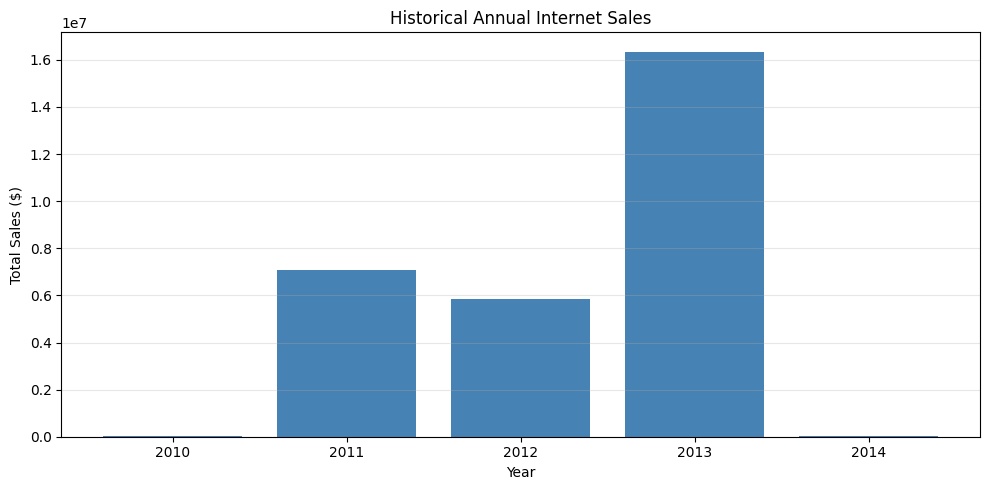

In [5]:
# STEP 4: Historical Annual Sales
annual_sales = (
    df.groupby("Year", as_index=False)["SalesAmount"]
    .sum()
)

print("\nHistorical Annual Sales:")
print(annual_sales.to_string(index=False))

# Plot annual sales
plt.figure(figsize=(10, 5))

plt.bar(
    annual_sales["Year"],
    annual_sales["SalesAmount"],
    color="steelblue"
)

plt.title("Historical Annual Internet Sales")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(annual_sales["Year"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# QUESTION 2: Forecast Sales for the Next Five Years
# Use complete historical years 2011-2013
# Exclude partial years 2010 and 2014

train = df[
    (df["Year"] >= 2011) &
    (df["Year"] <= 2013)
].copy()

# Aggregate sales by month
monthly_sales = (
    train.set_index("OrderDate")["SalesAmount"]
    .resample("MS")
    .sum()
    .reset_index()
)

monthly_sales.columns = ["OrderDate", "SalesAmount"]

# Create time index
monthly_sales["t"] = np.arange(len(monthly_sales))

# Extract month for seasonal effects
monthly_sales["Month"] = monthly_sales["OrderDate"].dt.month

print("\nMonthly Sales:")
print(monthly_sales.head())


Monthly Sales:
   OrderDate  SalesAmount  t  Month
0 2011-01-01  469823.9148  0      1
1 2011-02-01  466334.9030  1      2
2 2011-03-01  485198.6594  2      3
3 2011-04-01  502073.8458  3      4
4 2011-05-01  561681.4758  4      5


In [7]:
# STEP 5: Build Linear Regression Model
# Create time trend and monthly dummy variables
X_train = pd.get_dummies(
    monthly_sales[["t", "Month"]],
    columns=["Month"],
    drop_first=True,
    dtype=int
)

y_train = monthly_sales["SalesAmount"]

# Fit regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict historical sales
monthly_sales["FittedSales"] = model.predict(X_train)

# Calculate model R-squared
r2 = r2_score(
    monthly_sales["SalesAmount"],
    monthly_sales["FittedSales"]
)

print("\nModel R-squared:", round(r2, 4))


Model R-squared: 0.6342


In [8]:
# STEP 6: Forecast the Next 60 Months (2014-2018)
future_dates = pd.date_range(
    start="2014-01-01",
    periods=60,
    freq="MS"
)

future = pd.DataFrame({
    "OrderDate": future_dates,
    "t": np.arange(
        len(monthly_sales),
        len(monthly_sales) + 60
    )
})

future["Month"] = future["OrderDate"].dt.month

# Create the same dummy variables as training data
X_future = pd.get_dummies(
    future[["t", "Month"]],
    columns=["Month"],
    drop_first=True,
    dtype=int
)

# Ensure future columns match training columns
X_future = X_future.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Predict future sales
future["ForecastSales"] = np.maximum(
    0,
    model.predict(X_future)
)

future["Year"] = future["OrderDate"].dt.year

# Aggregate monthly forecasts into annual forecasts
annual_forecast = (
    future.groupby("Year", as_index=False)["ForecastSales"]
    .sum()
)

print("\nFive-Year Sales Forecast:")
print(
    annual_forecast.to_string(
        index=False,
        formatters={
            "ForecastSales": "${:,.2f}".format
        }
    )
)


Five-Year Sales Forecast:
 Year  ForecastSales
 2014 $19,032,544.90
 2015 $23,670,557.10
 2016 $28,308,569.31
 2017 $32,946,581.52
 2018 $37,584,593.72


In [9]:
# QUESTION 3: Which Product Generates the Most Sales?
# Calculate summary statistics by product
product_summary = (
    df.groupby("EnglishProductName")
    .agg(
        TotalSales=("SalesAmount", "sum"),
        TotalQuantity=("OrderQuantity", "sum"),
        AverageSales=("SalesAmount", "mean"),
        NumberOfTransactions=("SalesAmount", "count")
    )
    .sort_values("TotalSales", ascending=False)
)

print("\nTop 10 Products by Total Sales:")
print(product_summary.head(10))

# Identify the best-selling product by revenue
best_product = product_summary.index[0]
best_sales = product_summary.iloc[0]["TotalSales"]

print("\nProduct with Highest Total Sales:")
print(best_product)

print("Total Sales: ${:,.2f}".format(best_sales))



Top 10 Products by Total Sales:
                           TotalSales  TotalQuantity  AverageSales  \
EnglishProductName                                                   
Mountain-200 Black, 46   1.373470e+06            620   2215.273465   
Mountain-200 Black, 42   1.363142e+06            614   2220.101129   
Mountain-200 Silver, 38  1.339463e+06            596   2247.420789   
Mountain-200 Silver, 46  1.301100e+06            580   2243.276032   
Mountain-200 Black, 38   1.294866e+06            582   2224.855913   
Mountain-200 Silver, 42  1.257435e+06            560   2245.418880   
Road-150 Red, 48         1.205877e+06            337   3578.270000   
Road-150 Red, 62         1.202299e+06            336   3578.270000   
Road-150 Red, 52         1.080638e+06            302   3578.270000   
Road-150 Red, 56         1.055590e+06            295   3578.270000   

                         NumberOfTransactions  
EnglishProductName                             
Mountain-200 Black, 46        

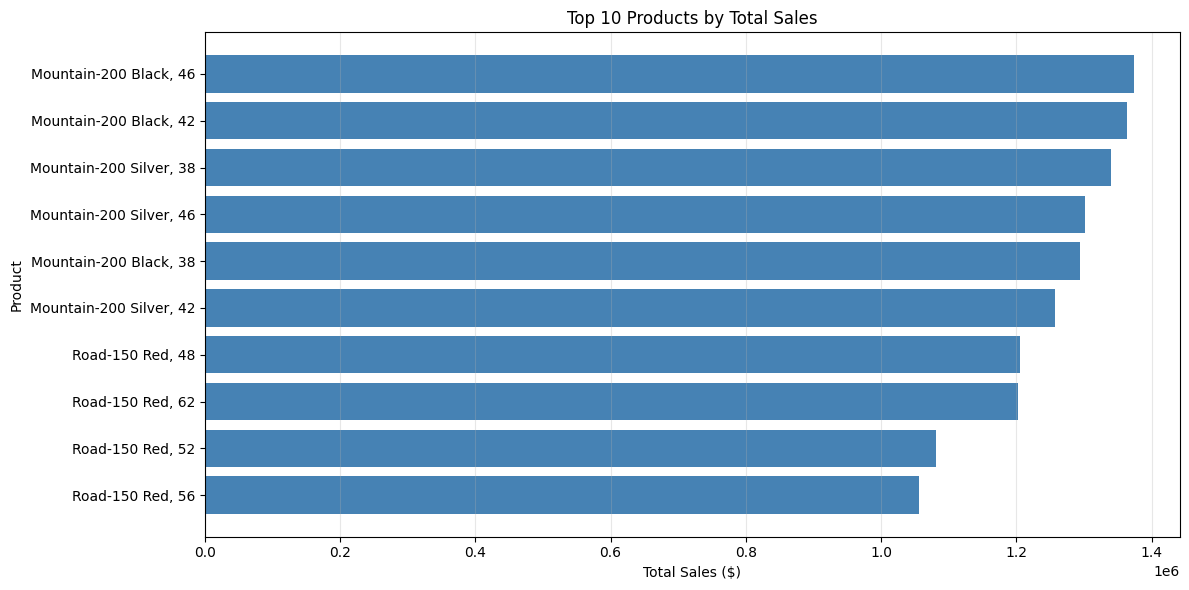

In [10]:
# STEP 7: Plot Top 10 Products
top10 = product_summary.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top10.index[::-1],
    top10["TotalSales"].iloc[::-1],
    color="steelblue"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

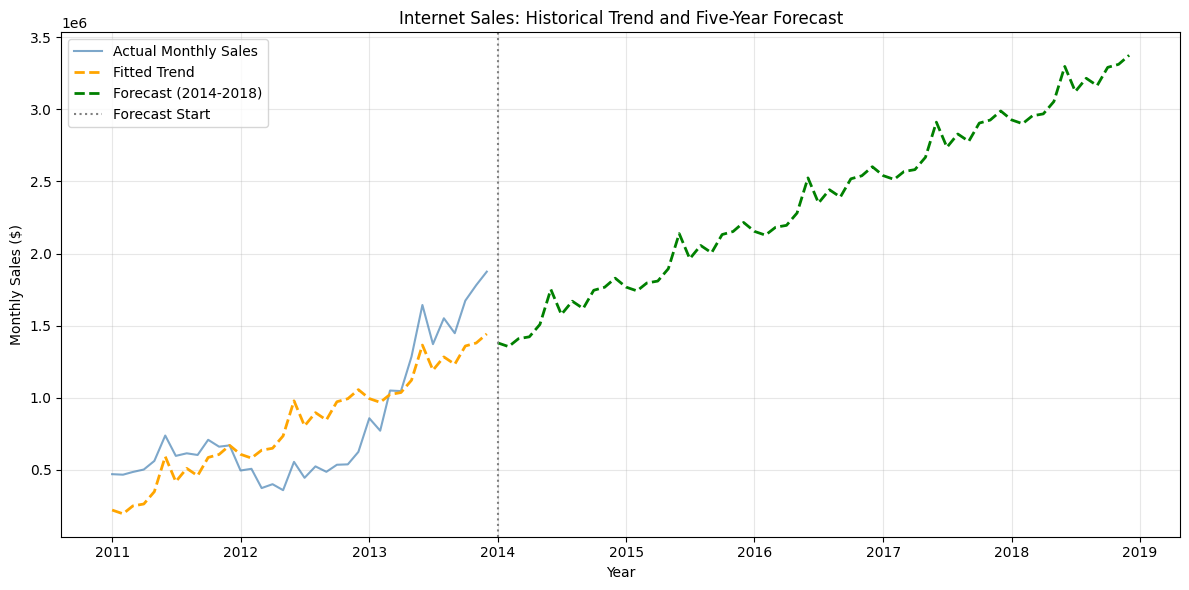

In [11]:
# QUESTION 4: Plot Sales Trend Line
plt.figure(figsize=(12, 6))

# Actual monthly sales
plt.plot(
    monthly_sales["OrderDate"],
    monthly_sales["SalesAmount"],
    label="Actual Monthly Sales",
    color="steelblue",
    alpha=0.7
)

# Fitted historical trend
plt.plot(
    monthly_sales["OrderDate"],
    monthly_sales["FittedSales"],
    label="Fitted Trend",
    color="orange",
    linestyle="--",
    linewidth=2
)

# Future sales forecast
plt.plot(
    future["OrderDate"],
    future["ForecastSales"],
    label="Forecast (2014-2018)",
    color="green",
    linestyle="--",
    linewidth=2
)

# Mark start of forecast period
plt.axvline(
    pd.Timestamp("2014-01-01"),
    color="gray",
    linestyle=":",
    label="Forecast Start"
)

plt.title("Internet Sales: Historical Trend and Five-Year Forecast")
plt.xlabel("Year")
plt.ylabel("Monthly Sales ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
plt.savefig(
    "Internet_Sales_Forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


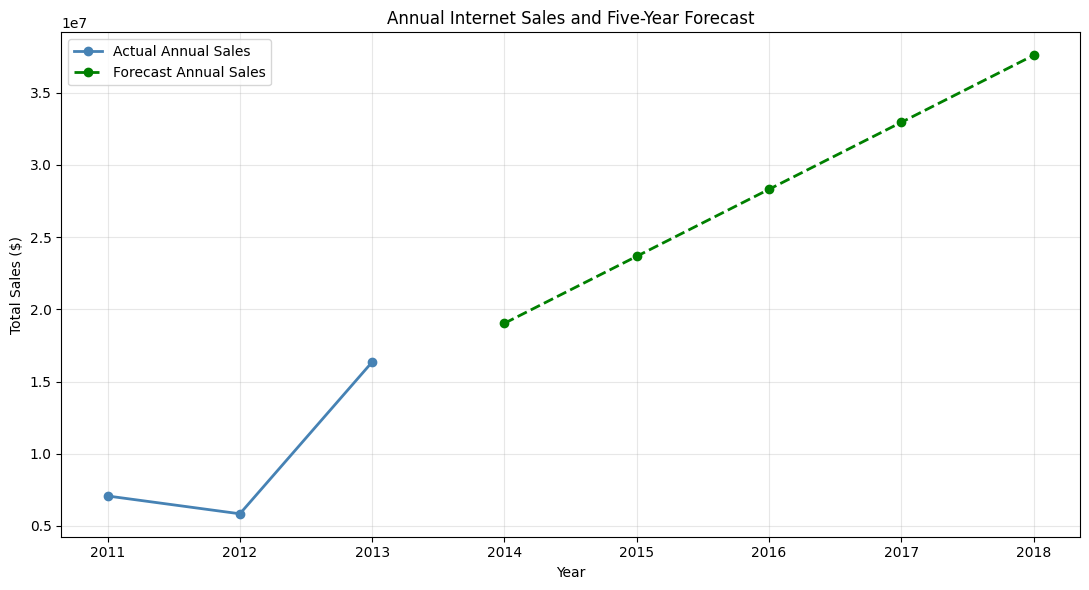

In [12]:
# STEP 8: Plot Annual Sales and Annual Forecast
# Only use complete historical years
historical_annual = annual_sales[
    annual_sales["Year"].between(2011, 2013)
]

plt.figure(figsize=(11, 6))

plt.plot(
    historical_annual["Year"],
    historical_annual["SalesAmount"],
    marker="o",
    label="Actual Annual Sales",
    color="steelblue",
    linewidth=2
)

plt.plot(
    annual_forecast["Year"],
    annual_forecast["ForecastSales"],
    marker="o",
    linestyle="--",
    label="Forecast Annual Sales",
    color="green",
    linewidth=2
)

plt.title("Annual Internet Sales and Five-Year Forecast")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(range(2011, 2019))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Annual_Internet_Sales_Forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# STEP 9: Export Results
annual_forecast.to_csv(
    "Five_Year_Sales_Forecast.csv",
    index=False
)

# Export product summary statistics
product_summary.to_csv(
    "Product_Sales_Summary.csv"
)

print("\nAll analysis completed successfully!")
print("Forecast and summary files have been saved.")



All analysis completed successfully!
Forecast and summary files have been saved.
